### Here are some very short, focused examples for a petrophysicist new to programming.

#### Keith R. Holdaway FGS

## 1. Loading Data: The Very Basics

#### Think of it like this:

A NumPy array is like a single log curve (e.g., just the GR values). It's a simple, powerful list of numbers.

A Pandas DataFrame is like the entire LAS file or spreadsheet. It has multiple curves (columns) and depth/index (rows). This is what you'll use 95% of the time.



### Example 1: Loading and Looking at Data

In [1]:
# Import the tools. We give them short nicknames ('pd', 'np') to type less.
import pandas as pd
import numpy as np

# Load your CSV file. It's like opening it in Excel.
# 'df' stands for "DataFrame" (your whole spreadsheet).
df = pd.read_csv('well_42-101.csv')

# The .head() method shows you the first 5 rows. Crucial first step!
print("First look at your data:")
print(df.head())

# The .info() method tells you about your curves: names, types, and if there's missing data.
print("\nInfo about your data:")
print(df.info())

# The .describe() method gives basic statistics (min, max, mean) for each numeric curve.
print("\nBasic statistics:")
print(df.describe())

First look at your data:
      DEPTH        GR        RT     NPHI     RHOB     DPHI
0  2500.000  85.49671  46.16965  0.16169  2.58081  0.04193
1  2500.125  87.25548  65.12765  0.17065  2.61306  0.02239
2  2500.250  90.32369  77.30452  0.17819  2.60050  0.03000
3  2500.375  93.28448  83.96409  0.19083  2.55555  0.05724
4  2500.500  93.34345  82.83286  0.21144  2.56522  0.05138

Info about your data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 801 entries, 0 to 800
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DEPTH   801 non-null    float64
 1   GR      801 non-null    float64
 2   RT      801 non-null    float64
 3   NPHI    801 non-null    float64
 4   RHOB    801 non-null    float64
 5   DPHI    801 non-null    float64
dtypes: float64(6)
memory usage: 37.7 KB
None

Basic statistics:
             DEPTH          GR          RT        NPHI        RHOB        DPHI
count   801.000000  801.000000  801.000000  801.000000

### Example 2: Accessing Data - NumPy Array vs. Pandas Column

In [2]:
# Get a single curve (e.g., Gamma Ray) as a Pandas Series (a single column).
gr_series = df['GR']
print("Pandas GR Series (shows index):")
print(gr_series.head())

# Get the same curve as a pure NumPy array (just the numbers, no depth index).
gr_array = df['GR'].values
print("\nNumPy GR Array (just numbers):")
print(gr_array[:5]) # first 5 values

# When to use which?
# Use Pandas for plotting, combining with depth, and data cleaning.
# Use NumPy when you need to do complex math operations on JUST the numbers.

Pandas GR Series (shows index):
0    85.49671
1    87.25548
2    90.32369
3    93.28448
4    93.34345
Name: GR, dtype: float64

NumPy GR Array (just numbers):
[85.49671 87.25548 90.32369 93.28448 93.34345]


### Example 3: Simple Calculations and Filtering

In [3]:
# Create a new column (e.g., Calculate Vshale from GR)
gr_min = 10  # Assume a clean sand value
gr_max = 180 # Assume a shale value

# This calculation runs for every row in the dataset instantly!
df['VSH'] = (df['GR'] - gr_min) / (gr_max - gr_min)

# Use NumPy to clamp the VSH values between 0 and 1.
# This is a great example of using a NumPy function on a Pandas column.
df['VSH'] = np.clip(df['VSH'], 0, 1)

# Filter data to show only points in a clean sand zone (e.g., VSH < 0.3)
clean_sand = df[df['VSH'] < 0.3]
print(f"Found {len(clean_sand)} samples in clean sand.")

Found 468 samples in clean sand.


## 2. High-Level Overview of Matplotlib for Petrophysics

### Matplotlib is like a digital drafting board for your logs. You can create multi-track cross-plots exactly how you want them, which is far more powerful than standard spreadsheet charting.

#### Key Capabilities for You:

Depth-Based Plots: The #1 feature. Plot any curve (GR, Resistivity, Density) on the X-axis against depth on the Y-axis to recreate a traditional log plot.

Multi-Track Plotting: Create a figure with 3, 4, or 5 tracks side-by-side (e.g., Track 1: GR, Track 2: Resistivity, Track 3: Density-Neutron).

Scatter Plots (Crossplots): Plot Density vs. Neutron to identify fluid and lithology trends (e.g., the classic "rhoHma" chart).

Customization: Control every detail: colors, line styles, shading, axes scales (linear vs. logarithmic for resistivity!), labels, and grids.

Shading Zones: Easily shade between curves or fill between a curve and a baseline to highlight zones (e.g., shade between GR and a cutoff to highlight shales).

## 3. Short Program to Illustrate the Power

#### This program loads data, calculates a new curve, and creates a multi-track plot—a task that would be very manual in other software.

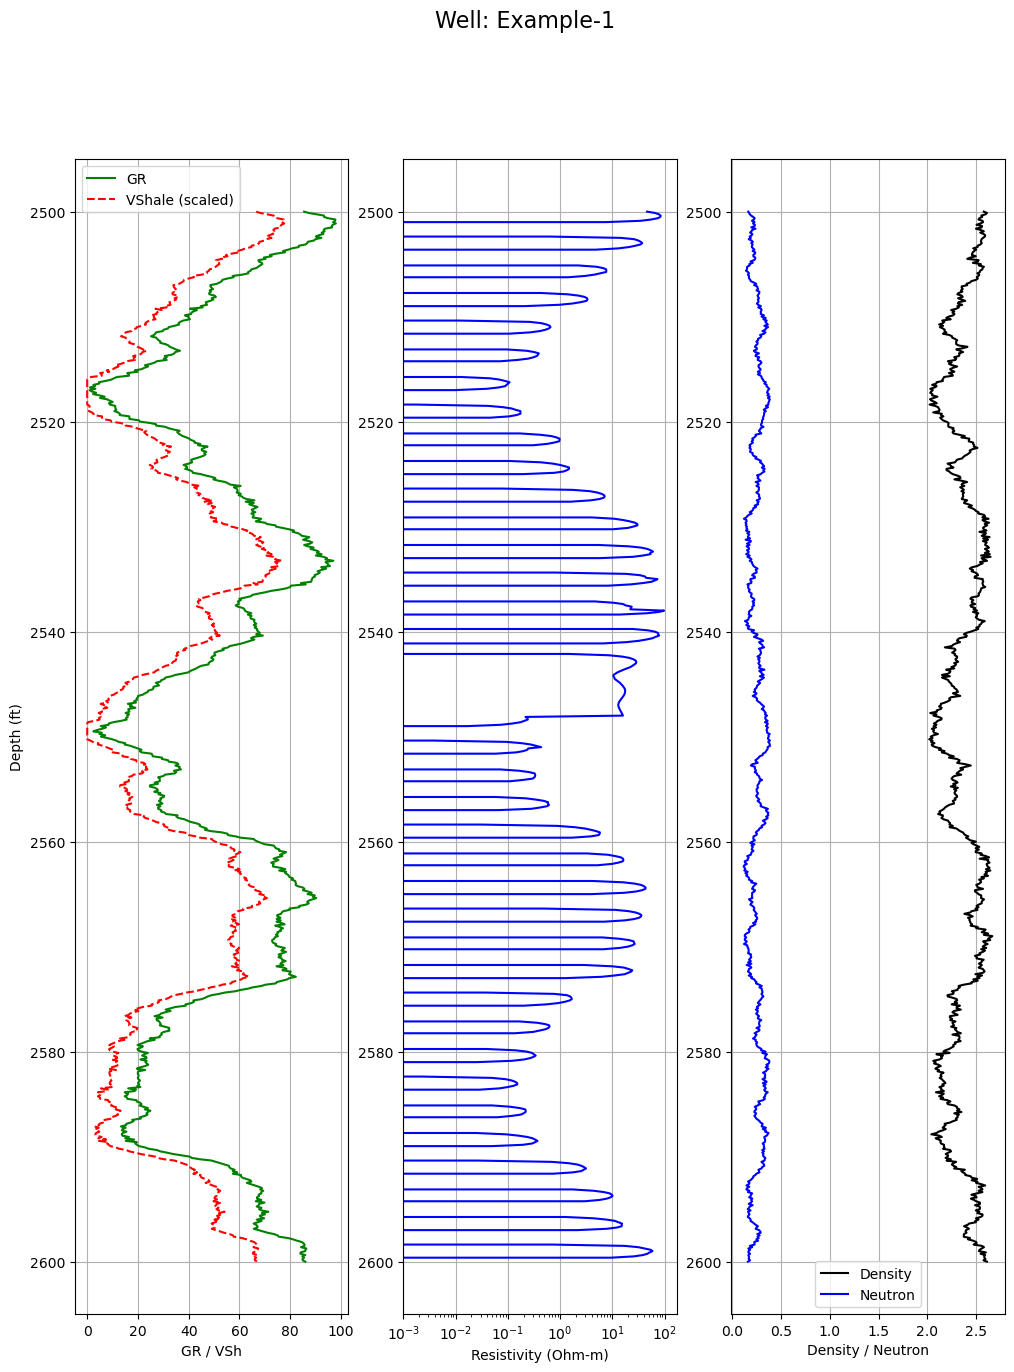

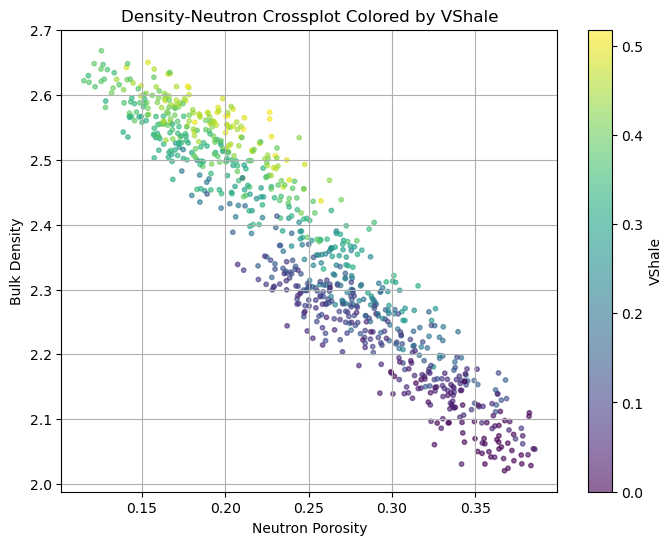

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the data
df = pd.read_csv('well_42-101.csv')
df['VSH'] = (df['GR'] - 10) / (180 - 10) # Simple Vshale
df['VSH'] = np.clip(df['VSH'], 0, 1)     # Clip to 0-1

# 1. Create a figure and axes for a 3-track plot
fig, axes = plt.subplots(1, 3, figsize=(12, 15)) # 1 row, 3 columns, large size
fig.suptitle('Well: Example-1', fontsize=16)

# Track 1: Gamma Ray and VShale
ax1 = axes[0]
ax1.plot(df['GR'], df['DEPTH'], 'green', label='GR')
ax1.plot(df['VSH'] * 150, df['DEPTH'], 'red', linestyle='--', label='VShale (scaled)') # Scale VSH to plot on same track
ax1.set_xlabel('GR / VSh')
ax1.set_ylabel('Depth (ft)')
ax1.grid(True)
ax1.legend()
ax1.invert_yaxis() # Absolutely critical! Inverts depth so it increases down.

# Track 2: Resistivity (Log Scale!)
ax2 = axes[1]
ax2.semilogx(df['RT'], df['DEPTH'], 'blue') # semilogx for log X-axis
ax2.set_xlabel('Resistivity (Ohm-m)')
ax2.grid(True)
ax2.invert_yaxis()

# Track 3: Density-Neutron
ax3 = axes[2]
ax3.plot(df['RHOB'], df['DEPTH'], 'black', label='Density')
ax3.plot(df['NPHI'], df['DEPTH'], 'blue', label='Neutron')
ax3.set_xlabel('Density / Neutron')
ax3.grid(True)
ax3.legend()
ax3.invert_yaxis()

# 2. Create a crossplot in a new window
plt.figure(figsize=(8, 6))
plt.scatter(df['NPHI'], df['RHOB'], c=df['VSH'], cmap='viridis', alpha=0.6, s=10)
plt.colorbar(label='VShale') # Color points by their VShale value
plt.xlabel('Neutron Porosity')
plt.ylabel('Bulk Density')
plt.title('Density-Neutron Crossplot Colored by VShale')
plt.grid(True)
plt.show()

### Why This is Powerful:

#### Automation: The entire calculation and plotting process is done in seconds. Rerun it instantly if your data changes.

#### Reproducibility: You have a complete record of exactly how you processed the data and created the plot.

#### Customization: You have total control over the plot appearance, which is impossible in many off-the-shelf petrophysics packages.

#### Integration: This is just the start. You can easily add machine learning, advanced statistics, or web applications on top of this foundation.

## Pandas or Numpy

### When to Use Which: A Petrophysicist's Guide

### Use Pandas (The Well Log Folder) For:

#### 1. Data I/O and Management:
This is your primary tool for loading, viewing, and managing the whole dataset.

In [5]:
import pandas as pd
# Load the entire "folder"
df = pd.read_csv('well_42-101.csv')
# See what's inside the folder
print(df.head())
# Check for missing values across all curves
print(df.isnull().sum())

      DEPTH        GR        RT     NPHI     RHOB     DPHI
0  2500.000  85.49671  46.16965  0.16169  2.58081  0.04193
1  2500.125  87.25548  65.12765  0.17065  2.61306  0.02239
2  2500.250  90.32369  77.30452  0.17819  2.60050  0.03000
3  2500.375  93.28448  83.96409  0.19083  2.55555  0.05724
4  2500.500  93.34345  82.83286  0.21144  2.56522  0.05138
DEPTH    0
GR       0
RT       0
NPHI     0
RHOB     0
DPHI     0
dtype: int64


#### 2. Depth-Based Operations and Plotting:
Pandas preserves the depth-index relationship, which is everything in petrophysics.

Text(0.5, 0, 'GR (API)')

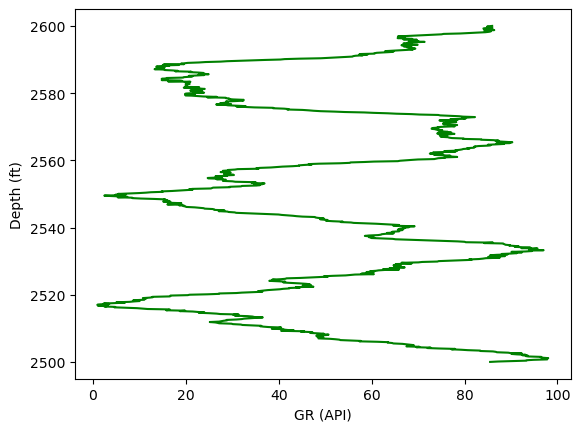

In [6]:
# This works because depth and GR are kept in perfect sync.
plt.plot(df['GR'], df['DEPTH'], 'g-')
plt.ylabel('Depth (ft)')
plt.xlabel('GR (API)')

#### 3. Calculating New Curves that Depend on Depth:
Creating a new curve that lives in your log folder.

In [7]:
# Calculate VShale using the linear GR method. This adds a new column to the DataFrame.
gr_clean = 15
gr_shale = 120
df['VSH_GR'] = (df['GR'] - gr_clean) / (gr_shale - gr_clean)

In [8]:
# Run this first to see the exact column names
print(df.columns.tolist())

# See what's inside the folder
print(df.head())

['DEPTH', 'GR', 'RT', 'NPHI', 'RHOB', 'DPHI', 'VSH_GR']
      DEPTH        GR        RT     NPHI     RHOB     DPHI    VSH_GR
0  2500.000  85.49671  46.16965  0.16169  2.58081  0.04193  0.671397
1  2500.125  87.25548  65.12765  0.17065  2.61306  0.02239  0.688147
2  2500.250  90.32369  77.30452  0.17819  2.60050  0.03000  0.717368
3  2500.375  93.28448  83.96409  0.19083  2.55555  0.05724  0.745566
4  2500.500  93.34345  82.83286  0.21144  2.56522  0.05138  0.746128


#### 4. Querying and Filtering Zones by Depth:
Using the depth index to select specific intervals.

In [9]:
# Example: if the column is actually called 'DEPTH'
sand_zone = df[(df['DEPTH'] >= 2500) & (df['DEPTH'] <= 2600) & (df['VSH_GR'] < 0.3)]

In [10]:
# Check the min and max of your VSH_GR curve
print(df['VSH_GR'].describe())

# Or, see what the highest VSH_GR value is in your target depth zone
target_depth_zone = df[(df['DEPTH'] >= 2500) & (df['DEPTH'] <= 2600)]
print(target_depth_zone['VSH_GR'].max())

count    801.000000
mean       0.335046
std        0.247448
min       -0.133996
25%        0.117124
50%        0.324230
75%        0.559315
max        0.790534
Name: VSH_GR, dtype: float64
0.790533619047619


### Use NumPy (The Calculator) For:

#### 1. Complex, Element-Wise Mathematical Operations:
NumPy is incredibly fast at applying a calculation to every element in a list.

In [11]:
import numpy as np

# Pull the RHOB curve out of the DataFrame to work on just the numbers
rhob_values = df['RHOB'].values # This is now a NumPy array

# Calculate a complex transform on the entire curve at once.
# Doing this directly on the Pandas column would be slower.
transformed_rhob = np.log(rhob_values) ** 2 + 5

# Now put the result back into the Pandas DataFrame to use it with depth.
df['TRANS_RHOB'] = transformed_rhob

#### 2. Advanced Mathematical Functions:
You need to compute something that requires a specialized function not built into basic math.

### The Difference Between NPHI and PHIE
NPHI (Neutron Porosity): This is the raw measurement from the tool. It measures the hydrogen concentration in the formation. It overestimates porosity in shaly zones because it counts the hydrogen in clay-bound water as "porosity". It also requires environmental corrections (e.g., for lithology).

Think of it as: Total Porosity (PHIT) or more precisely, the apparent porosity as if the rock was a clean sandstone.

PHIE (Effective Porosity): This is a corrected, interpreted value. It represents the pore space that is connected and can contribute to fluid flow (hydrocarbons and water). It excludes the volume occupied by clay-bound water.

Think of it as: The useful porosity.

Using NPHI instead of PHIE in a pay zone calculation will underestimate shale volume and overestimate water saturation, potentially making you miss a productive zone.

In [12]:
# Calculate the Archie Formation Factor (F = a / phi^m)
# First, get the porosity as a NumPy array
phi_values = df['NPHI'].values

a = 1.0   # tortuosity factor
m = 2.0   # cementation exponent

# NumPy makes it easy to handle division by zero (it will put 'inf' instead of crashing)
F = a / (phi_values ** m)

# Put the result back into the DataFrame
df['F'] = F

#### 3. Masking and Filtering Based on Complex Value Logic:
You want to find all values that meet a certain mathematical condition.

In [13]:
# Find all points where the zone is a hydrocarbon-bearing sand (high RT, low VSH)
rt_values = df['RT'].values
vsh_values = df['VSH_GR'].values

# Create a "mask" - a list of True/False values for each depth
hydrocarbon_mask = (rt_values > 10) & (vsh_values < 0.50)

# Use the mask to select only those rows from the entire DataFrame
hydrocarbon_zones = df[hydrocarbon_mask]
print(f"Found {len(hydrocarbon_zones)} samples in potential pay zones.")

Found 71 samples in potential pay zones.


In [14]:
# Replace 'DEPTH' with the correct column name from Step 1
correct_depth_column = 'DEPTH' 

min_depth = df[correct_depth_column].min()
max_depth = df[correct_depth_column].max()

print(f"\nYour data ranges from {min_depth} to {max_depth} feet.")


Your data ranges from 2500.0 to 2600.0 feet.


In [15]:
# USE THE CORRECT COLUMN NAME AND A VALID RANGE FROM STEPS 1-3
correct_depth_column = 'DEPTH'  # <-- CHANGE THIS
new_top = 2500                 # <-- CHANGE THIS
new_bottom = 2600              # <-- CHANGE THIS

# 1. First, just filter by depth.
depth_filtered = df[(df[correct_depth_column] >= new_top) & (df[correct_depth_column] <= new_bottom)]
print(f"Found {len(depth_filtered)} samples in depth range {new_top}-{new_bottom} ft")

# 2. If the number above is > 0, now add the VShale and Resistivity filters.
if len(depth_filtered) > 0:
    pay_zone_mask = (depth_filtered['RT'] > 30) & (depth_filtered['VSH_GR'] < 0.80)
    hydrocarbon_zones = depth_filtered[pay_zone_mask]
    print(f"Found {len(hydrocarbon_zones)} samples in potential pay zones.")

    # Now this .describe() will show real statistics!
    if len(hydrocarbon_zones) > 0:
        print(hydrocarbon_zones[['DEPTH', 'GR', 'RT']].describe())
    else:
        print("No pay zones found in that depth interval. Try relaxing your RT or VSH cutoffs.")
else:
    print("No data found in the specified depth interval. Please check the range.")

Found 801 samples in depth range 2500-2600 ft
Found 55 samples in potential pay zones.
             DEPTH         GR         RT
count    55.000000  55.000000  55.000000
mean   2541.411364  82.200151  51.019438
std      30.084225  10.091150  16.935696
min    2500.000000  62.118140  30.155600
25%    2532.062500  74.908830  36.420175
50%    2538.000000  85.895870  46.169650
75%    2564.312500  89.325490  62.428115
max    2599.375000  97.783630  97.753720


### How to Generate PHIE (Simple Methods)
You need to correct the neutron log for the presence of shale. Here are two common methods, implemented in Python.

#### Method 1: The Simple Shale Correction (Most Common)
This method assumes the Neutron log responds linearly to shale content.

#### Formula:
PHIE = NPHI - (VSH * NPHI_Shale)

#### Where:

NPHI_Shale is the average neutron porosity value in a nearby 100% shale zone.



In [16]:
# Step 1: Find the NPHI value in a shale zone
# Manually pick a depth interval that is pure shale (high GR, low resistivity)
shale_zone = df[(df['DEPTH'] >= 2500) & (df['DEPTH'] <= 2600)]
nphi_shale = shale_zone['NPHI'].mean() # Calculate the average NPHI in that shale
print(f"Average NPHI in shale zone: {nphi_shale:.3f}")

# Step 2: Calculate Effective Porosity
# Assume you've already calculated a VSH curve (e.g., 'VSH_GR')
df['PHIE'] = df['NPHI'] - (df['VSH_GR'] * nphi_shale)

# IMPORTANT: Clip the values. PHIE can't be negative.
df['PHIE'] = df['PHIE'].clip(lower=0.0)

# Now you can use PHIE for your pay zone calculation!
pay_zone_mask = (df['RT'] > 20) & (df['VSH_GR'] < 0.25) & (df['PHIE'] > 0.1) # Added a porosity cutoff!
hydrocarbon_zones = df[pay_zone_mask]

Average NPHI in shale zone: 0.249


#### Method 2: Using the Density-Neutron Crossplot (Better)
This is more accurate because it corrects for both shale and lithology effects. It uses the Density porosity (DPHI) as a reference.

Assumption: In a clean, liquid-bearing zone, Density and Neutron porosities should be similar. The difference between them (DeltaPHI) is largely due to shale and light hydrocarbons.

#### Formula:
PHIE = (NPHI + DPHI) / 2 (for a quick approximation in shaly sand)

But a better, more robust equation is:
PHIE = ( (NPHI**2 + DPHI**2) / 2 )**0.5 (Root-Mean-Square)

First, you need to calculate Density Porosity (DPHI).

In [17]:
# Define parameters for DPHI calculation. These are for a SANDSTONE matrix.
rho_ma = 2.65  # Matrix density (g/cc) for Quartz
rho_fl = 1.0   # Fluid density (g/cc) for fresh mud filtrate

# Calculate Density Porosity (DPHI)
df['DPHI'] = (rho_ma - df['RHOB']) / (rho_ma - rho_fl)

# Calculate Effective Porosity using RMS method
df['PHIE_RMS'] = np.sqrt( (df['NPHI']**2 + df['DPHI']**2) / 2 )

# Clip the values
df['PHIE_RMS'] = df['PHIE_RMS'].clip(lower=0.0, upper=1.0)

# Now use this more robust PHIE for your analysis!
pay_zone_mask = (df['RT'] > 20) & (df['VSH_GR'] < 0.25) & (df['PHIE_RMS'] > 0.1)
hydrocarbon_zones = df[pay_zone_mask]

#### Recommendation
For testing code and initial looks: Use NPHI.

For any serious analysis: Use Method 1 (Shale Correction). It's the standard first-pass approach for a shaly sand problem and is easy to implement.

For a more advanced analysis: Use Method 2 (Density-Neutron). It's more powerful as it automatically handles some lithology variations.